### PROBLEM STATEMENT

Cardiovascular diseases (CVDs) are one of the leading causes of death worldwide. Early detection of heart disease is essential to reduce the risk of severe complications and improve patient outcomes. Healthcare professionals often need support in identifying high-risk patients based on various medical factors such as age, blood pressure, cholesterol levels, chest pain type, and ECG results.

### OBJECTIVE

The objective of this project is to analyze patient health data and build machine learning models that can accurately predict the presence of heart disease. By comparing multiple classification algorithms and selecting the best-performing model, the project aims to assist hospitals and healthcare providers in early diagnosis and preventive care.

### TASK 1 : DATA ANALYSIS REPORT

In [232]:
import pandas as pd
import numpy as np

In [233]:
values = pd.read_csv("values.csv")

In [234]:
values.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [235]:
labels = pd.read_csv("labels.csv")

In [236]:
labels.head()

,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [237]:
values.shape

(180, 14)

In [238]:
labels.shape

(180, 2)

In [239]:
df = pd.merge(values , labels, on = "patient_id")

In [240]:
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [241]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [242]:
df.shape

(180, 15)

In [243]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [244]:
df.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [245]:
df.duplicated().sum()

np.int64(0)

In [246]:
df.nunique()

patient_id                              180
slope_of_peak_exercise_st_segment         3
thal                                      3
resting_blood_pressure                   36
chest_pain_type                           4
num_major_vessels                         4
fasting_blood_sugar_gt_120_mg_per_dl      2
resting_ekg_results                       3
serum_cholesterol_mg_per_dl             118
oldpeak_eq_st_depression                 34
sex                                       2
age                                      40
max_heart_rate_achieved                  73
exercise_induced_angina                   2
heart_disease_present                     2
dtype: int64

In [247]:
numerical_cols = df.select_dtypes(include=['int64' , 'float64']).columns
print("Numerical columns:")
print(numerical_cols)

Numerical columns:
Index(['slope_of_peak_exercise_st_segment', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')


In [248]:
categorical_cols = df.select_dtypes(include=['object']).columns
print("Categorical columns:")
print(categorical_cols)

Categorical columns:
Index(['patient_id', 'thal'], dtype='object')


EDA (EXPLORATORY DATA ANALYSIS)

In [249]:
import matplotlib.pyplot as plt
import seaborn as sns

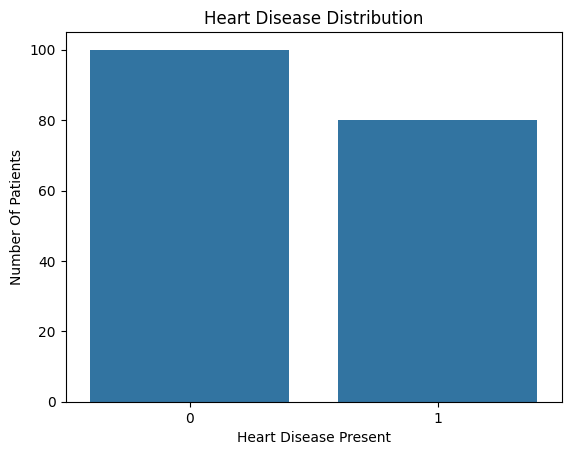

In [250]:
#Target Variable Distribution
sns.countplot(x = "heart_disease_present" , data=df)
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Present")
plt.ylabel("Number Of Patients")

plt.show()

Observation:

From the graph:
- Class 0 (No Heart Disease) has about 100 patients.
- Class 1 (Heart Disease Present) has about 80 patients.
- "I created a count plot of the target variable (heart_disease_present) to understand its distribution. The dataset contains slightly more patients without heart disease than patients with heart disease. Since both classes are reasonably represented, the dataset is fairly balanced and suitable for training classification models."

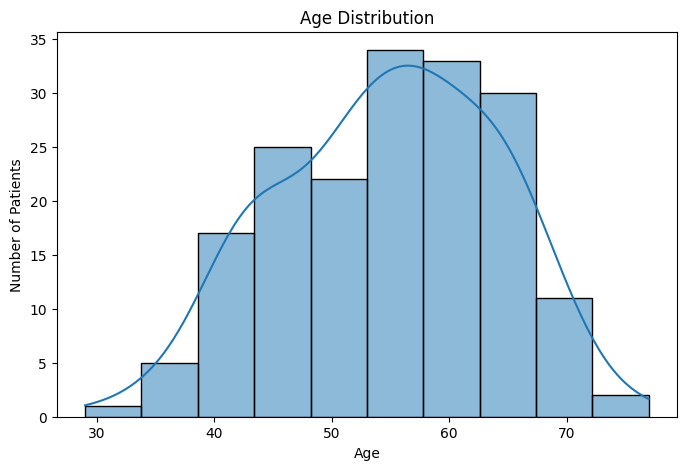

In [251]:
plt.figure(figsize=(8,5))
sns.histplot(df["age"], bins = 10, kde = True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

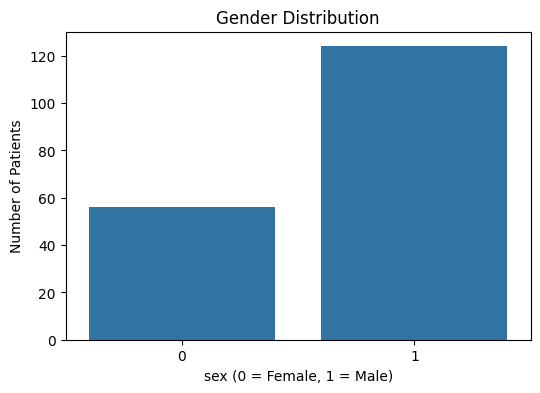

In [252]:
plt.figure(figsize=(6,4))
sns.countplot(x="sex" , data=df)
plt.title("Gender Distribution")
plt.xlabel("sex (0 = Female, 1 = Male)")
plt.ylabel("Number of Patients")

plt.show()

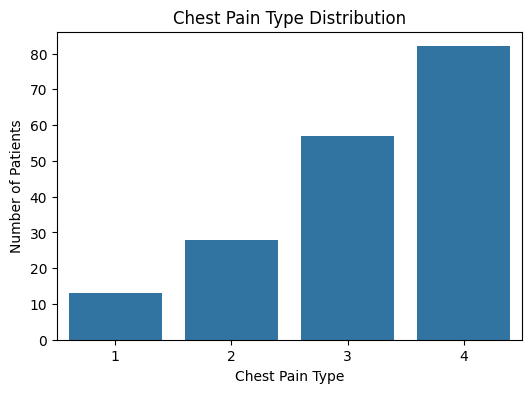

In [253]:
plt.figure(figsize=(6,4))
sns.countplot(x="chest_pain_type",data=df)
plt.title("Chest Pain Type Distribution")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")

plt.show()

<Axes: xlabel='chest_pain_type', ylabel='count'>

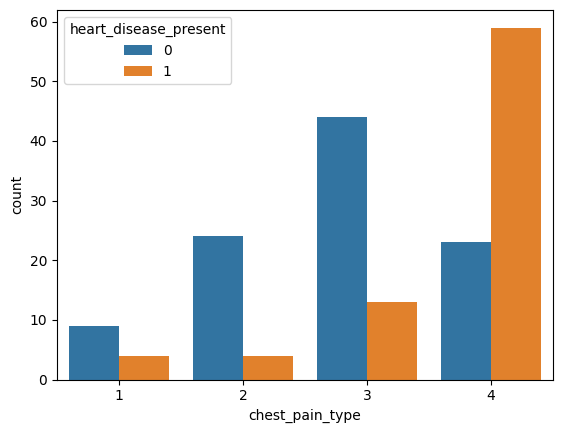

In [254]:
sns.countplot(x = "chest_pain_type" , hue = "heart_disease_present" , data=df)

- "I compared chest pain type with the target variable. I observed that patients with Chest Pain Type 4 have the highest number of heart disease cases, whereas Types 1 and 2 are mostly associated with patients who do not have heart disease."

<Axes: xlabel='sex', ylabel='count'>

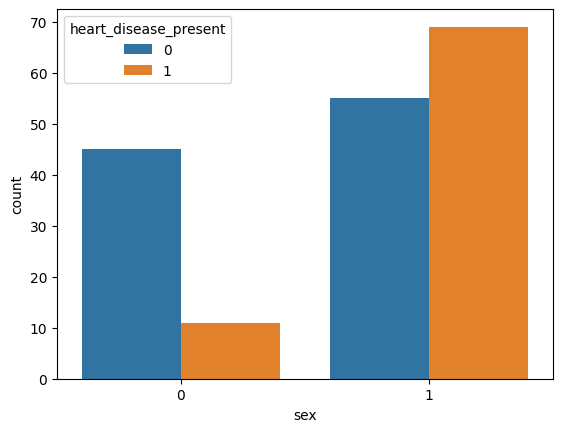

In [255]:
sns.countplot(x = "sex" , hue = "heart_disease_present" , data=df)

- Male patients show a higher number of heart disease cases.
- Female patients have fewer heart disease cases.
- Gender appears to be an important feature for prediction."

<Axes: xlabel='exercise_induced_angina', ylabel='count'>

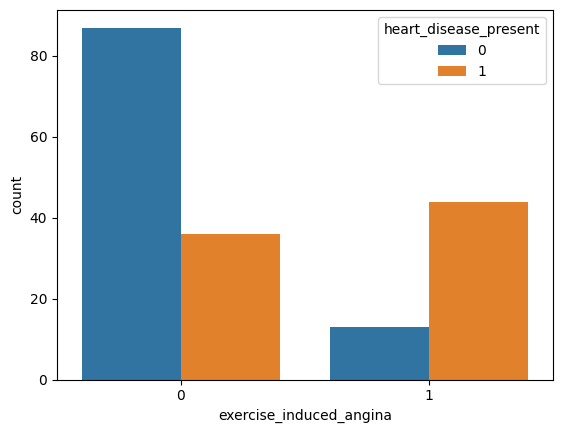

In [256]:
sns.countplot(x = "exercise_induced_angina" , hue = "heart_disease_present" , data=df)

- "I compared exercise-induced angina with the target variable. I observed that patients who experience exercise-induced angina have a higher number of heart disease cases. Therefore, this feature is important for predicting heart disease."

<Axes: xlabel='thal', ylabel='count'>

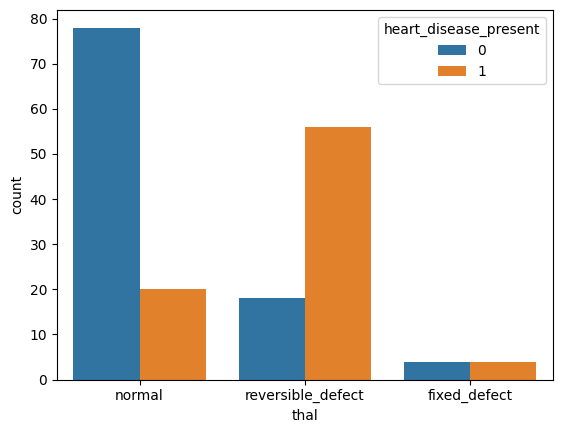

In [257]:
sns.countplot(x = "thal" , hue = "heart_disease_present" , data=df)

- The distribution of heart disease cases varies across different thal categories. Patients with reversible defect and fixed defect thal test results show a higher proportion of heart disease cases compared to patients with normal thal results.

<Axes: xlabel='fasting_blood_sugar_gt_120_mg_per_dl', ylabel='count'>

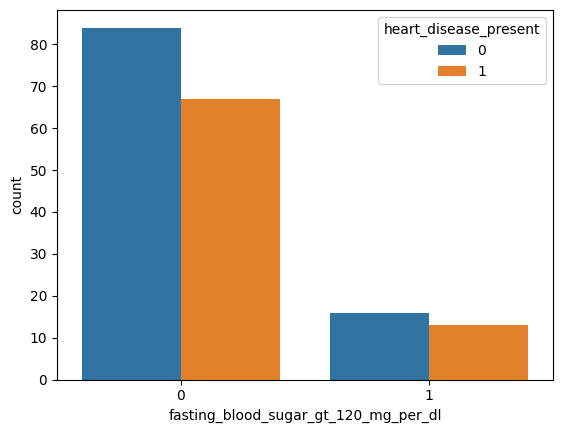

In [258]:
sns.countplot(x = "fasting_blood_sugar_gt_120_mg_per_dl" , hue = "heart_disease_present" ,data=df)

- "I compared fasting blood sugar with the target variable. Most patients have blood sugar levels below or equal to 120 mg/dL. The graph does not show a strong difference in heart disease cases between the two blood sugar groups, so this feature appears to have a weaker relationship with heart disease."

 MANUAL LABEL ENCODING

In [259]:
df["thal"] = df["thal"].map({"normal" : 0 , "fixed_defect" : 1 , "reversible_defect" : 2})

In [260]:
df["thal"].head()

0    0
1    0
2    0
3    2
4    2
Name: thal, dtype: int64

- "I used manual Label Encoding by applying the map() function to convert the categorical values in the thal column into numeric values so that machine learning algorithms could process them."

In [261]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    int64  
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [262]:
df.drop("patient_id" , axis=1, inplace=True)

In [263]:
df.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,0,128,2,0,0,2,308,0.0,1,45,170,0,0
1,2,0,110,3,0,0,0,214,1.6,0,54,158,0,0
2,1,0,125,4,3,0,2,304,0.0,1,77,162,1,1
3,1,2,152,4,0,0,0,223,0.0,1,40,181,0,1
4,3,2,178,1,0,0,2,270,4.2,1,59,145,0,0


In [264]:
df.dtypes

slope_of_peak_exercise_st_segment         int64
thal                                      int64
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
heart_disease_present                     int64
dtype: object

CORRELATION HEATMAP

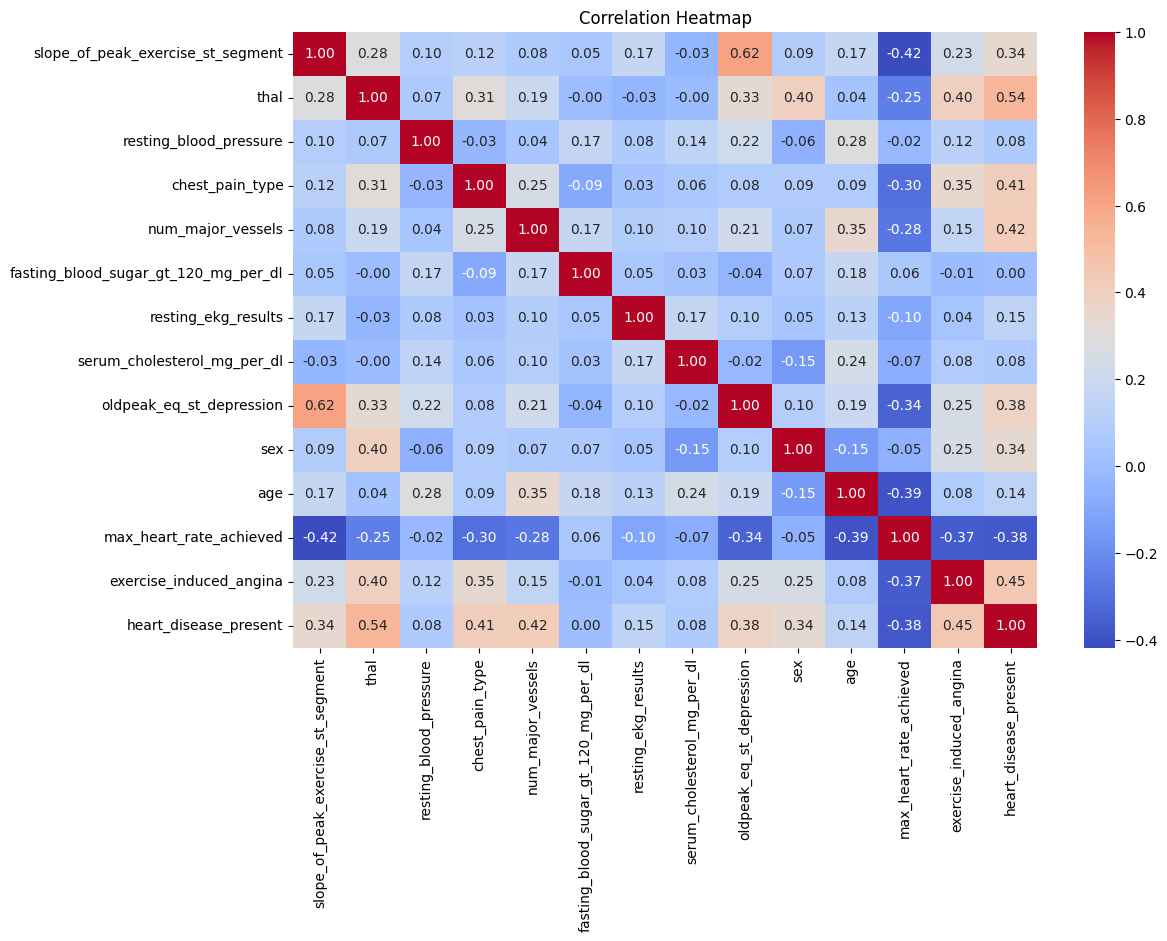

In [265]:
plt.figure(figsize = (12,8))
sns.heatmap(df.corr(), annot = True , cmap = "coolwarm" , fmt = ".2f")
plt.title("Correlation Heatmap")

plt.show()

<Axes: ylabel='serum_cholesterol_mg_per_dl'>

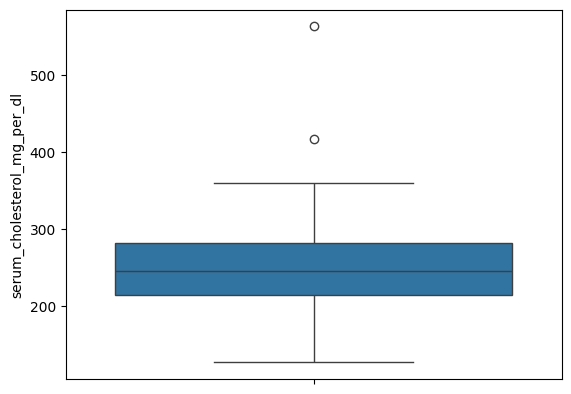

In [266]:
sns.boxplot(df["serum_cholesterol_mg_per_dl"])

- "Although a few outliers were observed in serum cholesterol, they were retained because they may represent genuine high-risk patients and are clinically meaningful."

<Axes: ylabel='age'>

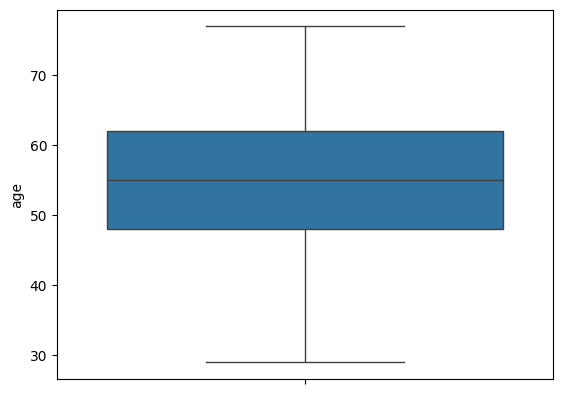

In [267]:
sns.boxplot(df["age"])

- "All values spread normally and No Outliers"

<Axes: ylabel='resting_blood_pressure'>

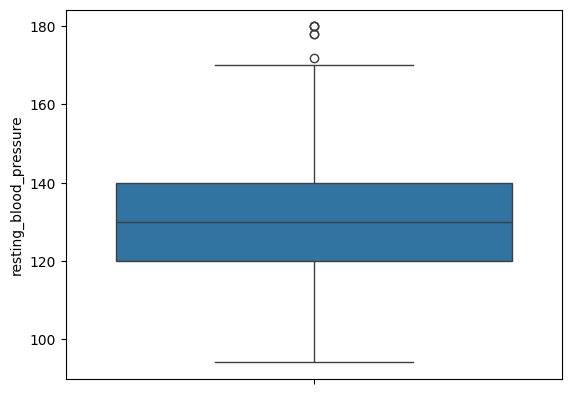

In [268]:
sns.boxplot(df["resting_blood_pressure"])

- "The outliers in resting blood pressure were retained as they represent realistic clinical observations."

<Axes: ylabel='max_heart_rate_achieved'>

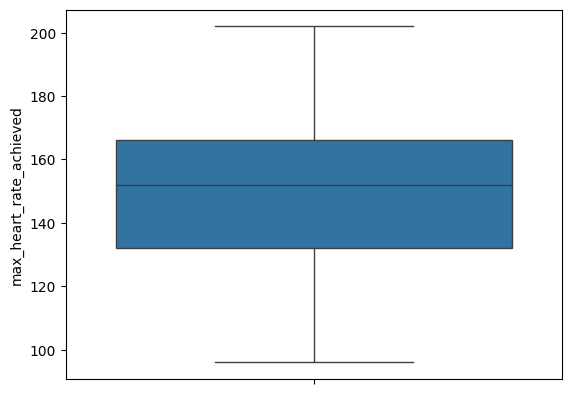

In [269]:
sns.boxplot(df["max_heart_rate_achieved"])

- "Distribution looks Normal."
- "No Outliers."

<Axes: ylabel='oldpeak_eq_st_depression'>

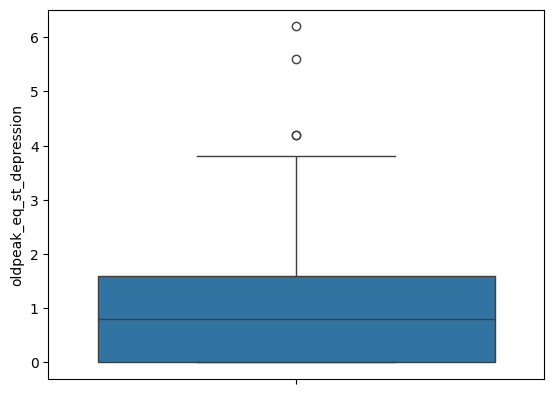

In [270]:
sns.boxplot(df["oldpeak_eq_st_depression"])

- "Outliers in oldpeak were retained because they may indicate severe cardiac abnormalities and are clinically significant."

### TASK 2 : Predicting Model Using Machine Learning Algorithms

TRAIN,TEST,SPLIT

In [271]:
from sklearn.model_selection import train_test_split

In [272]:
X = df.drop("heart_disease_present" , axis=1)
y = df["heart_disease_present"]

In [273]:
X_train , X_test , y_train , y_test = train_test_split( X, y , test_size = 0.2 , random_state = 42)

In [274]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(144, 13)
(36, 13)
(144,)
(36,)


In [275]:
df.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,0,128,2,0,0,2,308,0.0,1,45,170,0,0
1,2,0,110,3,0,0,0,214,1.6,0,54,158,0,0
2,1,0,125,4,3,0,2,304,0.0,1,77,162,1,1
3,1,2,152,4,0,0,0,223,0.0,1,40,181,0,1
4,3,2,178,1,0,0,2,270,4.2,1,59,145,0,0


In [276]:
df.columns

Index(['slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

In [277]:
print (X.columns)

Index(['slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina'],
      dtype='object')


In [278]:
print(y.head())

0    0
1    0
2    1
3    1
4    0
Name: heart_disease_present, dtype: int64


FEATURE SCALING

In [279]:
#STANDARD SCALER
#StandardScaler converts the data so that it has a mean of 0 and a standard deviation of 1.

In [280]:
from sklearn.preprocessing import StandardScaler

In [281]:
scaler = StandardScaler()

In [282]:
X_train_scaled = scaler.fit_transform(X_train)

In [283]:
X_test_scaled = scaler.transform(X_test)

In [284]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_train_scaled_df.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,-0.832405,1.188096,-1.261680,0.881143,-0.713122,-0.447214,0.996546,-1.583965,-0.868275,0.696086,-1.562503,0.377275,-0.696086
1,-0.832405,1.188096,-0.321541,0.881143,-0.713122,-0.447214,0.996546,0.757613,-0.868275,0.696086,-2.231152,0.286426,1.436604
2,0.744784,-0.885672,-0.967886,0.881143,-0.713122,-0.447214,-1.010484,1.204642,0.216598,0.696086,-1.339620,1.422036,-0.696086
3,0.744784,1.188096,1.088668,0.881143,2.367566,-0.447214,0.996546,-0.455750,0.035786,-1.436604,1.112094,-1.621399,-0.696086
4,-0.832405,-0.885672,0.501081,-0.185114,-0.713122,-0.447214,-1.010484,1.885828,-0.868275,0.696086,1.000652,0.377275,-0.696086


In [285]:
df["thal"].unique()

array([0, 2, 1])

In [286]:
df["thal"].isnull().sum()

np.int64(0)

#### LOGISTIC REGRESSION

In [287]:
#PREDICTION
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(random_state = 42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

In [288]:
print(type(X_train_scaled))
print(type(X_test_scaled))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [289]:
lr = LogisticRegression(random_state = 42)
lr.fit(X_train_scaled,y_train)
y_pred_lr = lr.predict(X_test_scaled)
print(y_pred_lr[:10])

[0 0 0 1 0 1 0 0 1 1]


In [290]:
#ACCURACY
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test , y_pred_lr)
print("Accuracy" , accuracy)

Accuracy 0.8333333333333334


"The Logistic Regression model achieved an accuracy of 83.33%, which means it correctly classified approximately 83 out of every 100 patients."

In [291]:
#CONFUSION MATRIX
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test , y_pred_lr)
print(cm)

[[15  1]
 [ 5 15]]


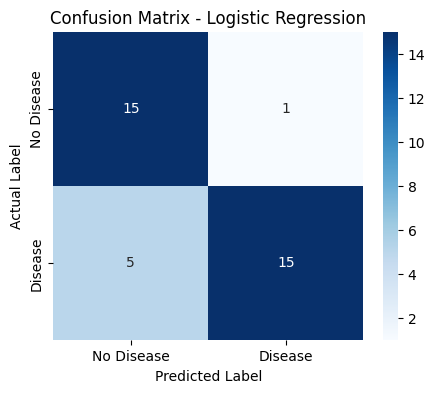

In [292]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot = True , fmt = 'd' , cmap = 'Blues',
            xticklabels = ['No Disease','Disease'],
            yticklabels = ['No Disease' ,'Disease'])

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [293]:
from sklearn.metrics import classification_report
print(classification_report(y_test ,y_pred_lr))

              precision    recall  f1-score   support

           0       0.75      0.94      0.83        16
           1       0.94      0.75      0.83        20

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



#### Hyperparameter Tuning

In [294]:
from sklearn.model_selection import GridSearchCV

In [295]:
param_grid_lr = {
    'C':[0.01,0.1,1,10,100],
    'solver':['liblinear','lbfgs'],
    'penalty':['l2']
}

In [296]:
lr = LogisticRegression(max_iter=100 , random_state=42)

grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_lr.fit(X_train_scaled,y_train)

,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'C': [0.01, 0.1, ...], 'penalty': ['l2'], 'solver': ['liblinear', 'lbfgs']}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [297]:
print("Best Parameters:",grid_lr.best_params_)
print("Best Cross Validation Accuracy:",grid_lr.best_score_)
best_lr = grid_lr.best_estimator_

Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
Best Cross Validation Accuracy: 0.847536945812808


In [298]:
y_pred_lr_tuned=best_lr.predict(X_test_scaled)
print("Accuracy:",accuracy_score(y_test,y_pred_lr_tuned))
print("\nConfusion_Matrix:\n",confusion_matrix(y_test,y_pred_lr_tuned))
print("\nClassification_Report:\n",classification_report(y_test,y_pred_lr_tuned))

Accuracy: 0.8333333333333334

Confusion_Matrix:
 [[15  1]
 [ 5 15]]

Classification_Report:
               precision    recall  f1-score   support

           0       0.75      0.94      0.83        16
           1       0.94      0.75      0.83        20

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



In [299]:
print("Accuracy Before Tuning :",accuracy_score(y_test,y_pred_lr))
print("Accuracy After Tuning:",accuracy_score(y_test,y_pred_lr))

Accuracy Before Tuning : 0.8333333333333334
Accuracy After Tuning: 0.8333333333333334


#### DECISION TREE CLASSIFIER

In [300]:
from sklearn.tree import DecisionTreeClassifier

In [301]:
#prediction
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train , y_train)
y_pred_dt = dt.predict(X_test)

In [302]:
print(type(X_train))
print(type(X_test))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


In [303]:
#Accuracy
accuracy = accuracy_score(y_test , y_pred_dt)
print("Accuracy" , accuracy)

Accuracy 0.7777777777777778


In [304]:
#Confusion Matrix
cm = confusion_matrix(y_test , y_pred_dt)
print(cm)

[[16  0]
 [ 8 12]]


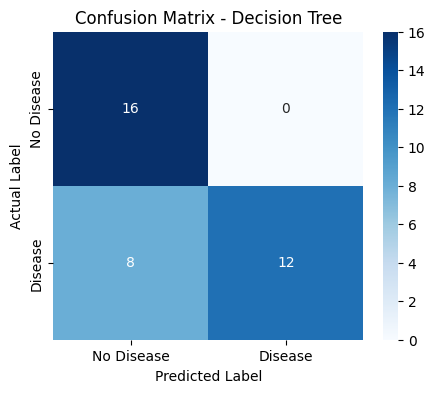

In [305]:
plt.figure(figsize=(5,4))
sns.heatmap(cm , annot=True , fmt = 'd', cmap='Blues',
             xticklabels = ['No Disease' , 'Disease'],
             yticklabels = ['No Disease' , 'Disease'])
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [306]:
#Classification Report
print(classification_report( y_test , y_pred_dt))

              precision    recall  f1-score   support

           0       0.67      1.00      0.80        16
           1       1.00      0.60      0.75        20

    accuracy                           0.78        36
   macro avg       0.83      0.80      0.78        36
weighted avg       0.85      0.78      0.77        36



"The Decision Tree correctly identified all healthy patients (16 out of 16), but it missed 8 patients who actually had heart disease. In healthcare, missing patients with heart disease (False Negatives) is a concern because it may delay treatment."

#### Hyperparameter Tuning

In [307]:
param_grid_dt = {
    "criterion":['gini','entropy'],
    "max_depth":[None,5,10,15],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]
}

In [308]:
dt = DecisionTreeClassifier(random_state=42)
grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_dt.fit(X_train_scaled,y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [309]:
print("Best Parameters:",grid_dt.best_params_)
print("Best Cross Validation Accuracy:",grid_dt.best_score_)
best_dt = grid_dt.best_estimator_

Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best Cross Validation Accuracy: 0.7852216748768474


In [310]:
y_pred_dt_tuned = best_dt.predict(X_test_scaled)
print("Accuracy after Tuning:",accuracy_score(y_test,y_pred_dt_tuned))

Accuracy after Tuning: 0.7777777777777778


In [311]:
print("Before Tuning:", accuracy_score(y_test, y_pred_dt))
print("After Tuning :", accuracy_score(y_test, y_pred_dt_tuned))

Before Tuning: 0.7777777777777778
After Tuning : 0.7777777777777778


#### RANDOM FOREST CLASSIFIER

In [312]:
from sklearn.ensemble import RandomForestClassifier

In [313]:
#Prediction
rf = RandomForestClassifier(random_state =42)
rf.fit(X_train , y_train)
y_pred_rf = rf.predict(X_test)

In [314]:
print(type(X_train))
print(type(X_test))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


In [315]:
#Accuracy
accuracy = accuracy_score(y_test , y_pred_rf)
print("Accuracy",accuracy)

Accuracy 0.8333333333333334


In [316]:
#confusionMatrix
cm = confusion_matrix(y_test , y_pred_rf)
print(cm)

[[16  0]
 [ 6 14]]


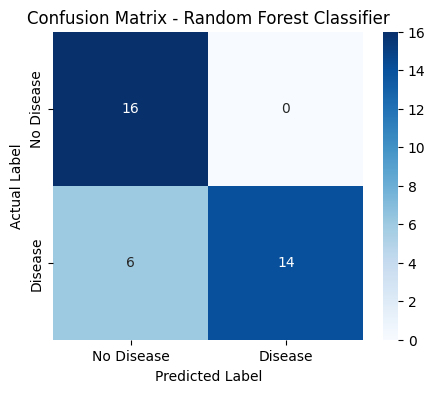

In [317]:
plt.figure(figsize=(5,4))
sns.heatmap(cm , annot = True , fmt = 'd', cmap= 'Blues',
            xticklabels = ['No Disease' , 'Disease'],
            yticklabels = ['No Disease' , 'Disease'])
plt.title("Confusion Matrix - Random Forest Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [318]:
#Classification Report
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.73      1.00      0.84        16
           1       1.00      0.70      0.82        20

    accuracy                           0.83        36
   macro avg       0.86      0.85      0.83        36
weighted avg       0.88      0.83      0.83        36



#### Hyperparameter Tuning

In [319]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [320]:
rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train_scaled, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [321]:
print("Best Parameters:", grid_rf.best_params_)
print("Best Cross Vaslidation Accuracy:",grid_rf.best_score_)
best_rf = grid_rf.best_estimator_

Best Parameters: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross Vaslidation Accuracy: 0.8408866995073891


In [322]:
y_pred_rf_tuned = best_rf.predict(X_test_scaled)
print("Accuracy After Tuning:", accuracy_score(y_test, y_pred_rf_tuned))

Accuracy After Tuning: 0.8611111111111112


In [323]:
print("Before Tuning:", accuracy_score(y_test, y_pred_rf))
print("After Tuning :", accuracy_score(y_test, y_pred_rf_tuned))

Before Tuning: 0.8333333333333334
After Tuning : 0.8611111111111112


Random Forest Hyperparameter Tuning:
- GridSearchCV with 5-fold cross-validation was used to tune the Random Forest classifier. After tuning, the model accuracy improved from 83.33% to 86.11%, indicating that the optimized hyperparameters improved the model's predictive performance.

#### SUPPORT VECTOR MACHINE(SVM)

In [324]:
from sklearn.svm import SVC

In [325]:
#Prediction
svc = SVC(random_state = 42)
svc.fit(X_train_scaled , y_train)
y_pred_svc = svc.predict(X_test_scaled)

In [326]:
print(type(X_train_scaled))
print(type(X_test_scaled))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [327]:
#Accuracy
accuracy = accuracy_score(y_test , y_pred_svc)
print("Accuracy" , accuracy)

Accuracy 0.8611111111111112


In [328]:
#Confusion Matrix
cm = confusion_matrix(y_test , y_pred_svc)
print(cm)

[[16  0]
 [ 5 15]]


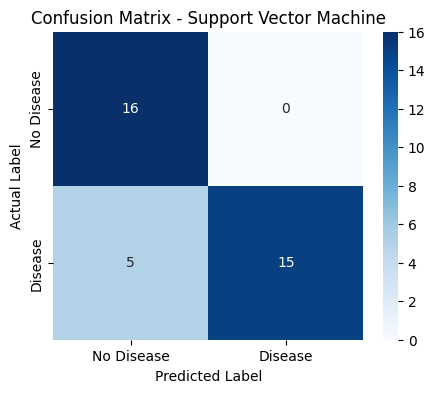

In [329]:
plt.figure(figsize=(5,4))
sns.heatmap(cm , annot = True , fmt = 'd' , cmap = 'Blues',
            xticklabels = ['No Disease' ,'Disease'],
            yticklabels = ['No Disease' ,'Disease'])
plt.title("Confusion Matrix - Support Vector Machine")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
          
plt.show()            

In [330]:
#Classification Report
print(classification_report(y_test , y_pred_svc))

              precision    recall  f1-score   support

           0       0.76      1.00      0.86        16
           1       1.00      0.75      0.86        20

    accuracy                           0.86        36
   macro avg       0.88      0.88      0.86        36
weighted avg       0.89      0.86      0.86        36



#### Hyperparameter Tuning

In [331]:
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

In [332]:
svm = SVC(random_state=42)
grid_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_svm.fit(X_train_scaled, y_train)

,estimator,SVC(random_state=42)
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


In [333]:
print("Best Parameters:", grid_svm.best_params_)
print("Best Cross Validation Accuracy:", grid_svm.best_score_)
best_svm = grid_svm.best_estimator_

Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross Validation Accuracy: 0.84064039408867


In [334]:
y_pred_svm_tuned = best_svm.predict(X_test_scaled)
print("Accuracy After Tuning:",
      accuracy_score(y_test, y_pred_svm_tuned))

Accuracy After Tuning: 0.8611111111111112


In [335]:
print("Before Tuning:", accuracy_score(y_test, y_pred_svc))
print("After Tuning :", accuracy_score(y_test, y_pred_svm_tuned))

Before Tuning: 0.8611111111111112
After Tuning : 0.8611111111111112


### TASK 3 : SUGGESTIONS TO HOSPITAL

- Conduct Regular Heart Health Screening Camps
- Promote Healthy Lifestyle Awareness
- Educate Patients About Risk Factors
- Encourage Regular Exercise
- Monitor High-Risk Patients
- Personalized Health Guidance
- Use Machine Learning for Early Prediction
- Improve Follow-Up Care

## MODEL COMPARISON REPORT

MODELS USED :
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- Support Vector Machine (SVM)

Baseline Model Comparison :

In [336]:
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score

In [337]:
comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svc),
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_svc),
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_svc),
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_svc),
    ]

})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.833333,0.9375,0.75,0.833333
1,Decision Tree,0.777778,1.0000,0.60,0.750000
2,Random Forest,0.833333,1.0000,0.70,0.823529
3,SVM,0.861111,1.0000,0.75,0.857143


In [338]:
comparison = comparison.round(3)
comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.833,0.938,0.75,0.833
1,Decision Tree,0.778,1.000,0.60,0.750
2,Random Forest,0.833,1.000,0.70,0.824
3,SVM,0.861,1.000,0.75,0.857


In [339]:
comparison = comparison.sort_values(by="Accuracy", ascending=False)
comparison

,Model,Accuracy,Precision,Recall,F1-Score
3,SVM,0.861,1.000,0.75,0.857
0,Logistic Regression,0.833,0.938,0.75,0.833
2,Random Forest,0.833,1.000,0.70,0.824
1,Decision Tree,0.778,1.000,0.60,0.750


After Hyperparameter Tuning comparison

In [340]:
tuned_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],
    "Before Tuning": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svc)
    ],
    "After Tuning": [
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_dt_tuned),
        accuracy_score(y_test, y_pred_rf_tuned),
        accuracy_score(y_test, y_pred_svm_tuned)
    ]
})

tuned_comparison = tuned_comparison.round(3)
tuned_comparison

,Model,Before Tuning,After Tuning
0,Logistic Regression,0.833,0.833
1,Decision Tree,0.778,0.778
2,Random Forest,0.833,0.861
3,SVM,0.861,0.861


### FEATURE IMPORTANCE

In [341]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
1,thal,0.168621
12,exercise_induced_angina,0.118447
3,chest_pain_type,0.118322
4,num_major_vessels,0.115391
8,oldpeak_eq_st_depression,0.107853
11,max_heart_rate_achieved,0.101961
10,age,0.070103
7,serum_cholesterol_mg_per_dl,0.056349
0,slope_of_peak_exercise_st_segment,0.056040
2,resting_blood_pressure,0.037490


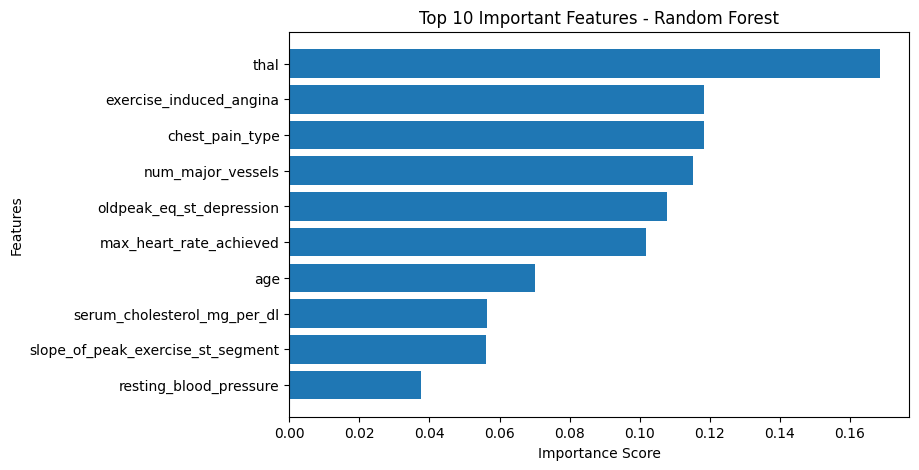

In [342]:
plt.figure(figsize=(8,5))

plt.barh(
    feature_importance['Feature'][:10],
    feature_importance['Importance'][:10]
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

### OBSERVATION

- Feature importance analysis was performed using the Random Forest model. The results indicate that the top contributing features to heart disease prediction were age, chest pain type, maximum heart rate achieved, oldpeak ST depression, and number of major vessels.

- This analysis helps identify the key factors associated with heart disease risk and improves the interpretability of the model.

### BEST MODEL FOR PRODUCTION

- Random Forest was selected as the final model for production.
- Although both Random Forest and SVM achieved the highest accuracy of 86.11%, Random Forest was chosen because:
- It achieved the highest accuracy after hyperparameter tuning.
- It improved from 83.33% to 86.11% after tuning.
- It is robust and performs well on classification tasks.
- It provides feature importance, helping identify the most influential factors contributing to heart disease prediction.

- Therefore, the tuned Random Forest model is recommended for deployment in the hospital to support early heart disease detection.

### CHALLENGES FACED

- Initially faced challenges while merging the values and labels datasets correctly to create a single dataset for analysis.
 
- Faced difficulty in converting the categorical feature thal into numerical values using label encoding.
 
- Initially used an incorrect mapping for the thal column, which resulted in NaN values. This issue was resolved by correcting the category names before encoding.
 
- Faced challenges in identifying which machine learning algorithms required feature scaling and which algorithms could work effectively without scaling.

- Selecting appropriate data preprocessing techniques, such as encoding categorical variables, feature scaling, handling missing values, and removing unnecessary columns, required careful analysis.

- Choosing the most suitable machine learning algorithms for heart disease prediction and understanding their strengths and limitations was an important part of the project.

- During model comparison, Random Forest and SVM achieved the same accuracy after hyperparameter tuning. Random Forest was selected as the final model because it showed improvement after tuning and provides feature importance, making it more interpretable for healthcare applications.

### CONCLUSION

- Four machine learning models were trained and evaluated using Logistic Regression,Decision Tree,Random Forest and SVM.
- This project successfully developed and evaluated multiple machine learning models for predicting the presence of heart disease. The dataset was preprocessed through data cleaning, exploratory data analysis (EDA), label encoding, train-test splitting, and feature scaling. Four classification algorithms—Logistic Regression, Decision Tree, Random Forest, and Support Vector Machine (SVM)—were trained and evaluated using Accuracy, Precision, Recall, and F1-Score.

- To further improve model performance, GridSearchCV was used for hyperparameter tuning. The tuned Random Forest model showed an improvement in accuracy from 83.33% to 86.11%, while the tuned SVM also achieved an accuracy of 86.11%. Since Random Forest improved after tuning and provides feature importance for better interpretability, it was selected as the final model for production.

- This model can assist healthcare professionals in the early detection of heart disease, enabling timely medical intervention and supporting better clinical decision-making. Although the model demonstrates good predictive performance, it should be used as a decision-support tool alongside medical expertise rather than as a replacement for clinical diagnosis.

- The developed model can assist healthcare professionals in early diagnosis and risk assessment of heart disease, enabling timely medical intervention and improved patient outcomes.

### FUTURE SCOPE

- Increase the dataset size and include additional health-related features.
  
- Explore advanced machine learning and deep learning models for improved prediction accuracy.

- Integrate the model into hospital systems for real-time decision support.

- Develop a web or mobile application for easy heart disease risk assessment.